In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna()

X = df.drop("target", axis=1).values
y = df["target"].values

print("Dataset Shape:", df.shape)

Dataset Shape: (302, 14)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(kernel="rbf", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

In [5]:
trained_models = {}
predictions = {}

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    trained_models[name] = model
    predictions[name] = model.predict(X_test_scaled)

    print(name, "training completed")

Logistic Regression training completed
Decision Tree training completed
Random Forest training completed
SVM training completed
KNN training completed


In [6]:
def calculate_metrics(actual, predicted):

    TP = np.sum((actual == 1) & (predicted == 1))
    TN = np.sum((actual == 0) & (predicted == 0))
    FP = np.sum((actual == 0) & (predicted == 1))
    FN = np.sum((actual == 1) & (predicted == 0))

    accuracy = (TP + TN) / len(actual)

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

In [7]:
results = []

for name, predicted in predictions.items():

    metrics = calculate_metrics(y_test, predicted)

    results.append({
        "Model": name,
        **metrics
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8033,0.8000,0.8485,0.8235
1,Decision Tree,0.8033,0.8182,0.8182,0.8182
2,Random Forest,0.7541,0.7647,0.7879,0.7761
3,SVM,0.7705,0.7714,0.8182,0.7941
4,KNN,0.7869,0.7778,0.8485,0.8116


In [8]:
bias_variance_results = []

for name, model in trained_models.items():

    train_predictions = model.predict(X_train_scaled)
    test_predictions = predictions[name]

    train_accuracy = np.mean(train_predictions == y_train)
    test_accuracy = np.mean(test_predictions == y_test)

    gap = train_accuracy - test_accuracy

    bias_variance_results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Generalization Gap": gap
    })

bias_variance_df = pd.DataFrame(bias_variance_results)

display(bias_variance_df.round(4))

,Model,Train Accuracy,Test Accuracy,Generalization Gap
0,Logistic Regression,0.8589,0.8033,0.0556
1,Decision Tree,1.0000,0.8033,0.1967
2,Random Forest,1.0000,0.7541,0.2459
3,SVM,0.9212,0.7705,0.1507
4,KNN,0.8963,0.7869,0.1094


In [9]:
for _, row in bias_variance_df.iterrows():

    train_acc = row["Train Accuracy"]
    test_acc = row["Test Accuracy"]
    gap = row["Generalization Gap"]

    print("\nModel:", row["Model"])

    if train_acc < 0.70 and test_acc < 0.70:
        print("Possible high bias / underfitting tendency")

    elif gap > 0.10:
        print("Possible high variance / overfitting tendency")

    else:
        print("Relatively balanced training and testing performance")


Model: Logistic Regression
Relatively balanced training and testing performance

Model: Decision Tree
Possible high variance / overfitting tendency

Model: Random Forest
Possible high variance / overfitting tendency

Model: SVM
Possible high variance / overfitting tendency

Model: KNN
Possible high variance / overfitting tendency


In [10]:
from scipy.stats import chi2

top_two = results_df.nlargest(2, "Accuracy")["Model"].tolist()

model_a, model_b = top_two

pred_a = predictions[model_a]
pred_b = predictions[model_b]

b = np.sum((pred_a == y_test) & (pred_b != y_test))
c = np.sum((pred_a != y_test) & (pred_b == y_test))

if b + c == 0:
    statistic = 0
    p_value = 1.0
else:
    statistic = (abs(b - c) - 1) ** 2 / (b + c)
    p_value = 1 - chi2.cdf(statistic, df=1)

print("Model A:", model_a)
print("Model B:", model_b)
print("Discordant A-correct/B-wrong:", b)
print("Discordant A-wrong/B-correct:", c)
print("McNemar Statistic:", round(statistic, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("The difference is statistically significant at 5% level.")
else:
    print("No statistically significant difference found at 5% level.")

Model A: Logistic Regression
Model B: Decision Tree
Discordant A-correct/B-wrong: 6
Discordant A-wrong/B-correct: 6
McNemar Statistic: 0.0833
P-value: 0.7728
No statistically significant difference found at 5% level.


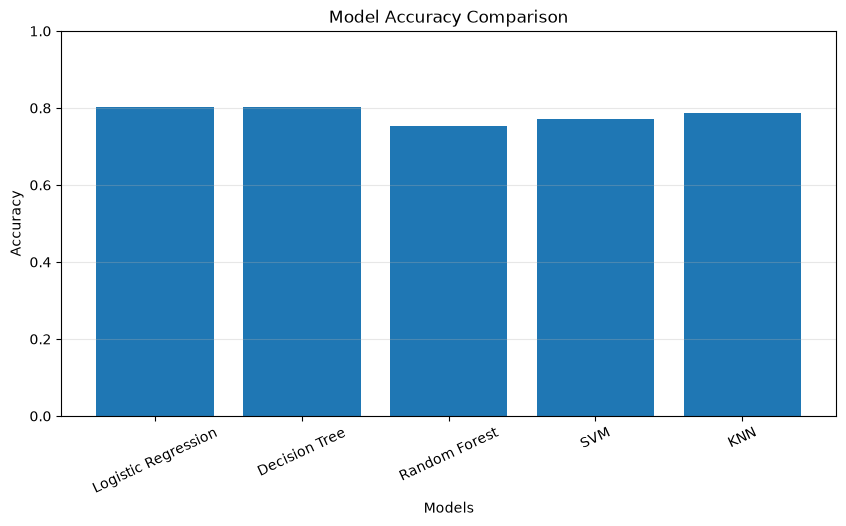

In [13]:
plt.figure(figsize=(10, 5))

plt.bar(results_df["Model"], results_df["Accuracy"])

plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")

plt.xticks(rotation=25)
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

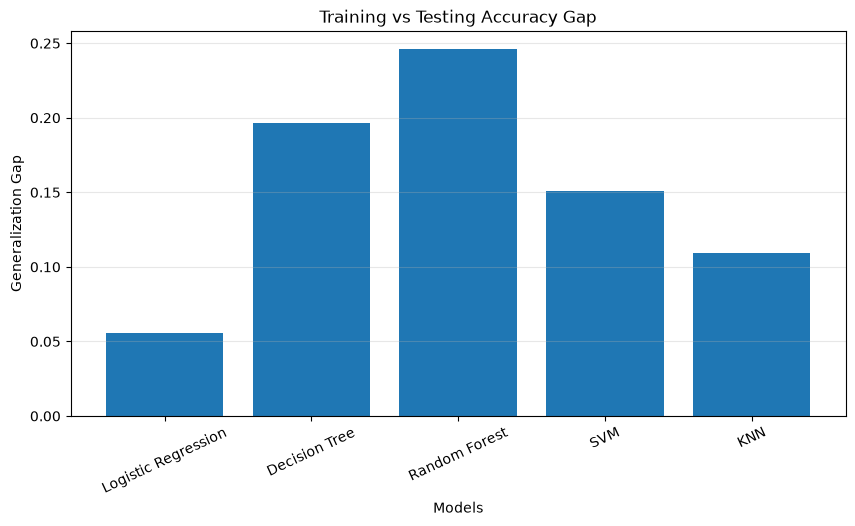

In [14]:
plt.figure(figsize=(10, 5))

plt.bar(
    bias_variance_df["Model"],
    bias_variance_df["Generalization Gap"]
)

plt.xlabel("Models")
plt.ylabel("Generalization Gap")
plt.title("Training vs Testing Accuracy Gap")

plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [15]:
best_model = results_df.loc[
    results_df["Accuracy"].idxmax(), "Model"
]

print("Best Model Based on Test Accuracy:", best_model)

print("""
Conclusion:

Different machine learning models show different performance
on the same heart disease dataset.

A large training-testing performance gap may indicate high variance.
Low performance on both datasets may indicate high bias.

McNemar's test helps determine whether two classifiers have
a statistically significant difference in their paired predictions.

Model selection should consider multiple evaluation metrics,
generalization performance, complexity, and statistical evidence.
""")

Best Model Based on Test Accuracy: Logistic Regression

Conclusion:

Different machine learning models show different performance
on the same heart disease dataset.

A large training-testing performance gap may indicate high variance.
Low performance on both datasets may indicate high bias.

McNemar's test helps determine whether two classifiers have
a statistically significant difference in their paired predictions.

Model selection should consider multiple evaluation metrics,
generalization performance, complexity, and statistical evidence.

